In [3]:
from google.colab import files
uploaded = files.upload()

Saving sales_data_sample.csv to sales_data_sample (1).csv


***Load and inspect the dataset***

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sales_data_sample.csv", encoding="ISO-8859-1")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (2823, 25)

Column names:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


***Check missing values and data types***

In [6]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302

***Select suitable features***

In [7]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:")
print(numeric_cols)

Numeric columns:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'MSRP']


***Prepare the clustering data***

In [8]:
candidate_features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "MSRP"
]

features = [col for col in candidate_features if col in df.columns]

if len(features) < 2:
    raise ValueError(
        "Expected sales features were not found. "
        "Check the column names printed in Step 1."
    )

X = df[features].copy()
X = X.replace([np.inf, -np.inf], np.nan).dropna()

print("Selected features:", features)
print("Data shape for clustering:", X.shape)
display(X.head())

Selected features: ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
Data shape for clustering: (2823, 4)


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
0,30,95.70,2871.00,95
1,34,81.35,2765.90,95
2,41,94.74,3884.34,95
3,45,83.26,3746.70,95
4,49,100.00,5205.27,95


***Normalize the data***

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Normalization completed.")
print("Scaled data shape:", X_scaled.shape)

Normalization completed.
Scaled data shape: (2823, 4)


***Apply the Elbow Method***

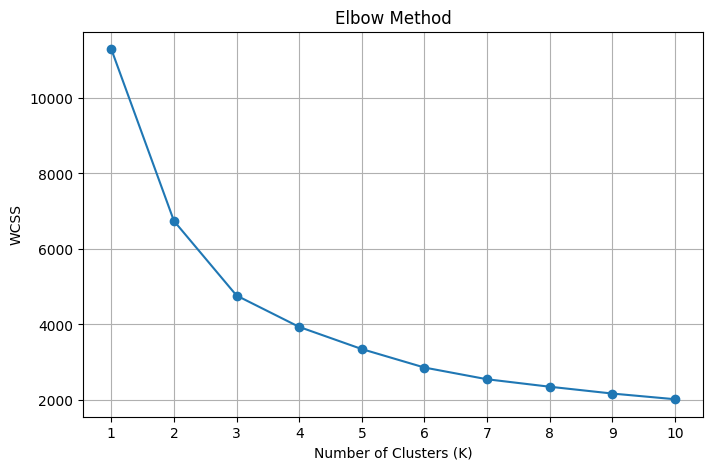

In [10]:
from sklearn.cluster import KMeans

wcss = []
for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

***Build the K-Means model***

In [13]:
k = 3
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to the corresponding cleaned rows
clustered_data = X.loc[X.index].copy()
clustered_data["Cluster"] = clusters

print("K-Means clustering completed.")
print("\nNumber of records in each cluster:")
print(clustered_data["Cluster"].value_counts().sort_index())

display(clustered_data.head())

K-Means clustering completed.

Number of records in each cluster:
Cluster
0    975
1    852
2    996
Name: count, dtype: int64


,QUANTITYORDERED,PRICEEACH,SALES,MSRP,Cluster
0,30,95.70,2871.00,95,2
1,34,81.35,2765.90,95,2
2,41,94.74,3884.34,95,1
3,45,83.26,3746.70,95,1
4,49,100.00,5205.27,95,1


***Visualize the clusters***

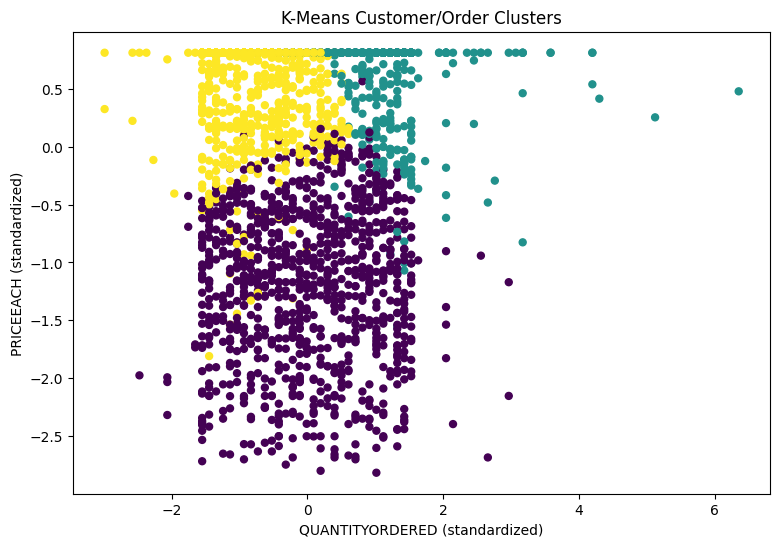

In [14]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=25
)
plt.xlabel(features[0] + " (standardized)")
plt.ylabel(features[1] + " (standardized)")
plt.title("K-Means Customer/Order Clusters")
plt.show()

In [15]:
#Hierarchical clustering
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hierarchical = AgglomerativeClustering(n_clusters=3)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical clustering completed.")
print("Cluster counts:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

print(
    "Silhouette score:",
    round(silhouette_score(X_scaled, hierarchical_labels), 4)
)

Hierarchical clustering completed.
Cluster counts:
0    1204
1     934
2     685
Name: count, dtype: int64
Silhouette score: 0.3153


In [16]:
clustered_data.to_csv("assignment5_clustered_results.csv", index=False)
print("Results saved to assignment5_clustered_results.csv")

Results saved to assignment5_clustered_results.csv


In [17]:
from google.colab import files
files.download("assignment5_clustered_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>